# 03. Logistic Regression & Algorithm Comparison: Demand Surge Classification
## Retail Sales Predictive Analytics & Time Series Forecasting

### Modeling Task:
Binary classification for high-demand surge detection and retail stockout prevention across $N=26,730$ validation observations.

### Problem Formulation:
In retail supply chain management, sales forecasts are frequently deployed not merely to estimate continuous quantities, but to trigger operational risk mitigation workflows (e.g., dispatching emergency distribution trucks or activating secondary warehouse stock).
- `1` = **Demand Surge**: Unit sales exceed the store-family historical 80th-percentile threshold ($\text{sales} > \tau_{s,f}$).
- `0` = **Normal Demand**: Unit sales are within normal operating bounds ($\text{sales} \le \tau_{s,f}$).

### Core Objectives:
1. **Zero Target Leakage:** Derive surge thresholds $\tau_{s,f}$ **strictly from historical training observations** (`2016-08-01` to `2017-07-31`).
2. **Out-of-Sample Decision Threshold Tuning:** Optimize the probability classification threshold strictly on a held-out temporal partition within training data (June–July 2017: 108,702 rows) without touching validation data.
3. **Algorithm Benchmarking:** Compare 4 classification configurations:
   - `DummyClassifier (Most Frequent Baseline)`
   - `Logistic Regression (Default Class Weighting, Threshold = 0.50)`
   - `Logistic Regression (Balanced Class Weighting, Threshold = 0.50)`
   - `Logistic Regression (Tuned Decision Threshold = 0.29)`
4. **Evaluation Metrics:** Accuracy, Precision, Recall, F1-Score, ROC-AUC, PR-AUC, and Confusion Matrix (TN, FP, FN, TP).
5. **The Deception of Accuracy:** Demonstrate why standard accuracy is a dangerous metric in retail event forecasting.

In [1]:
import sys
from pathlib import Path

# Add project root to sys.path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

from src.config import (
    MODELS_DIR,
    REPORTS_DIR,
    FIGURES_DIR,
    SURGE_TARGET_COL,
    TARGET_COL,
    RANDOM_SEED,
)
from src.preprocess import load_processed_datasets
from src.logistic_regression import (
    LOGISTIC_NUMERIC_FEATURES,
    LOGISTIC_CATEGORICAL_FEATURES,
    build_logistic_regression_pipeline,
    find_optimal_threshold_on_train,
    train_and_evaluate_classifier,
    plot_confusion_matrices,
    plot_roc_and_pr_curves,
    plot_logistic_coefficients,
)

sns.set_theme(style="whitegrid", palette="muted")
print("Environment and logistic regression modules initialized successfully.")

Environment and logistic regression modules initialized successfully.


## 1. Load Processed Datasets & Target Distribution Inspection
We load the preprocessed datasets and verify the binary class distribution for `is_high_sales` on train and validation sets.

In [2]:
train_df, val_df = load_processed_datasets()
if train_df is None or val_df is None:
    raise FileNotFoundError("Processed datasets missing. Run notebooks/01_data_exploration_and_preprocessing.ipynb first.")

train_pos = int(train_df[SURGE_TARGET_COL].sum())
val_pos = int(val_df[SURGE_TARGET_COL].sum())

print(f"Training Partition ({len(train_df):,} rows):")
print(f"  - Normal Demand (0): {len(train_df) - train_pos:,} ({(1 - train_pos/len(train_df)):.2%})")
print(f"  - Demand Surge  (1): {train_pos:,} ({train_pos/len(train_df):.2%})")

print(f"\nValidation Holdout ({len(val_df):,} rows):")
print(f"  - Normal Demand (0): {len(val_df) - val_pos:,} ({(1 - val_pos/len(val_df)):.2%})")
print(f"  - Demand Surge  (1): {val_pos:,} ({val_pos/len(val_df):.2%})")

feature_cols = LOGISTIC_NUMERIC_FEATURES + LOGISTIC_CATEGORICAL_FEATURES
X_train = train_df[feature_cols].copy()
y_train = train_df[SURGE_TARGET_COL].values
X_val = val_df[feature_cols].copy()
y_val = val_df[SURGE_TARGET_COL].values

for col in LOGISTIC_CATEGORICAL_FEATURES:
    X_train[col] = X_train[col].astype(str)
    X_val[col] = X_val[col].astype(str)

Training Partition (648,648 rows):
  - Normal Demand (0): 537,640 (82.89%)
  - Demand Surge  (1): 111,008 (17.11%)

Validation Holdout (26,730 rows):
  - Normal Demand (0): 22,267 (83.30%)
  - Demand Surge  (1): 4,463 (16.70%)


## 2. Out-of-Sample Decision Threshold Calibration
To tune the classification threshold without in-sample target leakage:
1. Training data is split chronologically into a sub-train set (`2016-08-01` to `2017-05-31`: 539,946 rows) and a calibration holdout (`2017-06-01` to `2017-07-31`: 108,702 rows).
2. A calibration model is fit strictly on the sub-train set.
3. Out-of-sample probabilities are generated on the calibration holdout to select the threshold $\tau^*$ maximizing F1-score.

In [3]:
print("Calibrating decision threshold strictly out-of-sample on training partitions...")
opt_thresh, train_sub_f1 = find_optimal_threshold_on_train(
    X_train=X_train,
    y_train=y_train,
    train_dates=train_df["date"],
    cutoff_date="2017-06-01",
    numeric_features=LOGISTIC_NUMERIC_FEATURES,
    categorical_features=LOGISTIC_CATEGORICAL_FEATURES,
    model_type="default",
)

print(f"Selected Out-of-Sample Optimal Decision Threshold: {opt_thresh:.4f} (Calibration F1: {train_sub_f1:.4f})")

Calibrating decision threshold strictly out-of-sample on training partitions...


Selected Out-of-Sample Optimal Decision Threshold: 0.2897 (Calibration F1: 0.5168)


## 3. Algorithm Training & Validation Benchmarking
We benchmark:
1. `DummyClassifier (Most Frequent)`: Zero-intelligence majority class baseline.
2. `Logistic Regression (Default, Threshold = 0.50)`: Unweighted standard classifier.
3. `Logistic Regression (Balanced, Threshold = 0.50)`: Inverse class frequency weighting.
4. `Logistic Regression (Tuned Threshold)`: Using the out-of-sample calibrated threshold.

In [4]:
model_definitions = [
    {"name": "DummyClassifier (Most Frequent)", "model_type": "dummy", "params": {}, "threshold": 0.5},
    {"name": "Logistic Regression (Default, Threshold = 0.5)", "model_type": "default", "params": {"class_weight": None}, "threshold": 0.5},
    {"name": "Logistic Regression (Balanced, Threshold = 0.5)", "model_type": "balanced", "params": {"class_weight": "balanced"}, "threshold": 0.5},
]

benchmark_results = []
cm_dict = {}
plot_results = {}
pipelines = {}

for m_def in model_definitions:
    name = m_def["name"]
    print(f"Fitting {name}...")
    pipe = build_logistic_regression_pipeline(
        numeric_features=LOGISTIC_NUMERIC_FEATURES,
        categorical_features=LOGISTIC_CATEGORICAL_FEATURES,
        model_type=m_def["model_type"],
        **m_def["params"],
    )
    
    metrics, y_proba, y_pred = train_and_evaluate_classifier(
        pipeline=pipe,
        X_train=X_train,
        y_train=y_train,
        X_val=X_val,
        y_val=y_val,
        threshold=m_def["threshold"],
    )
    
    benchmark_results.append({"Model": name, **metrics})
    pipelines[name] = pipe
    cm_dict[name] = np.array([
        [metrics["True_Negatives"], metrics["False_Positives"]],
        [metrics["False_Negatives"], metrics["True_Positives"]],
    ])
    plot_results[name] = {"metrics": metrics, "proba": y_proba, "pred": y_pred}

# Evaluate the Out-of-Sample Tuned Threshold model
y_val_proba = plot_results["Logistic Regression (Default, Threshold = 0.5)"]["proba"]
y_val_pred_opt = (y_val_proba >= opt_thresh).astype(int)
cm_opt = confusion_matrix(y_val, y_val_pred_opt)

tuned_name = f"Logistic Regression (Tuned Threshold = {opt_thresh:.2f})"
tuned_metrics = {
    "Model": tuned_name,
    "Accuracy": round(float(accuracy_score(y_val, y_val_pred_opt)), 4),
    "Precision": round(float(precision_score(y_val, y_val_pred_opt, zero_division=0)), 4),
    "Recall": round(float(recall_score(y_val, y_val_pred_opt, zero_division=0)), 4),
    "F1": round(float(f1_score(y_val, y_val_pred_opt, zero_division=0)), 4),
    "ROC_AUC": round(float(roc_auc_score(y_val, y_val_proba)), 4),
    "PR_AUC": round(float(average_precision_score(y_val, y_val_proba)), 4),
    "Threshold": round(opt_thresh, 4),
    "True_Negatives": int(cm_opt[0, 0]),
    "False_Positives": int(cm_opt[0, 1]),
    "False_Negatives": int(cm_opt[1, 0]),
    "True_Positives": int(cm_opt[1, 1]),
    "Fit_Time_Sec": plot_results["Logistic Regression (Default, Threshold = 0.5)"]["metrics"]["Fit_Time_Sec"],
}

benchmark_results.append(tuned_metrics)
cm_dict[tuned_name] = cm_opt
plot_results[tuned_name] = {"metrics": tuned_metrics, "proba": y_val_proba, "pred": y_val_pred_opt}

results_df = pd.DataFrame(benchmark_results)
display_cols = ["Model", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC", "Threshold", "Fit_Time_Sec"]
print("\n--- Classification Benchmark Comparison Table ---")
display(results_df[display_cols].sort_values(by="F1", ascending=False))

Fitting DummyClassifier (Most Frequent)...


Fitting Logistic Regression (Default, Threshold = 0.5)...


Fitting Logistic Regression (Balanced, Threshold = 0.5)...



--- Classification Benchmark Comparison Table ---


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Threshold,Fit_Time_Sec
3,Logistic Regression (Tuned Threshold = 0.29),0.7465,0.3416,0.5590,0.4241,0.7518,0.4180,0.2897,34.66
2,"Logistic Regression (Balanced, Threshold = 0.5)",0.6151,0.2705,0.7694,0.4003,0.7529,0.4159,0.5000,44.88
1,"Logistic Regression (Default, Threshold = 0.5)",0.8212,0.4524,0.3363,0.3858,0.7518,0.4180,0.5000,34.66
0,DummyClassifier (Most Frequent),0.8330,0.0000,0.0000,0.0000,0.5000,0.1670,0.5000,6.41


## 4. Benchmark Metrics Persistence
We export the complete classification benchmark metrics to `reports/logistic_regression_metrics.csv`.

In [5]:
metrics_csv = REPORTS_DIR / "logistic_regression_metrics.csv"
results_df.to_csv(metrics_csv, index=False)
print(f"Saved classification benchmark metrics to: {metrics_csv}")

Saved classification benchmark metrics to: C:\retail-sales-prediction-and-forecasting\reports\logistic_regression_metrics.csv


## 5. Diagnostic Visualizations: Confusion Matrices, ROC, and PR Curves

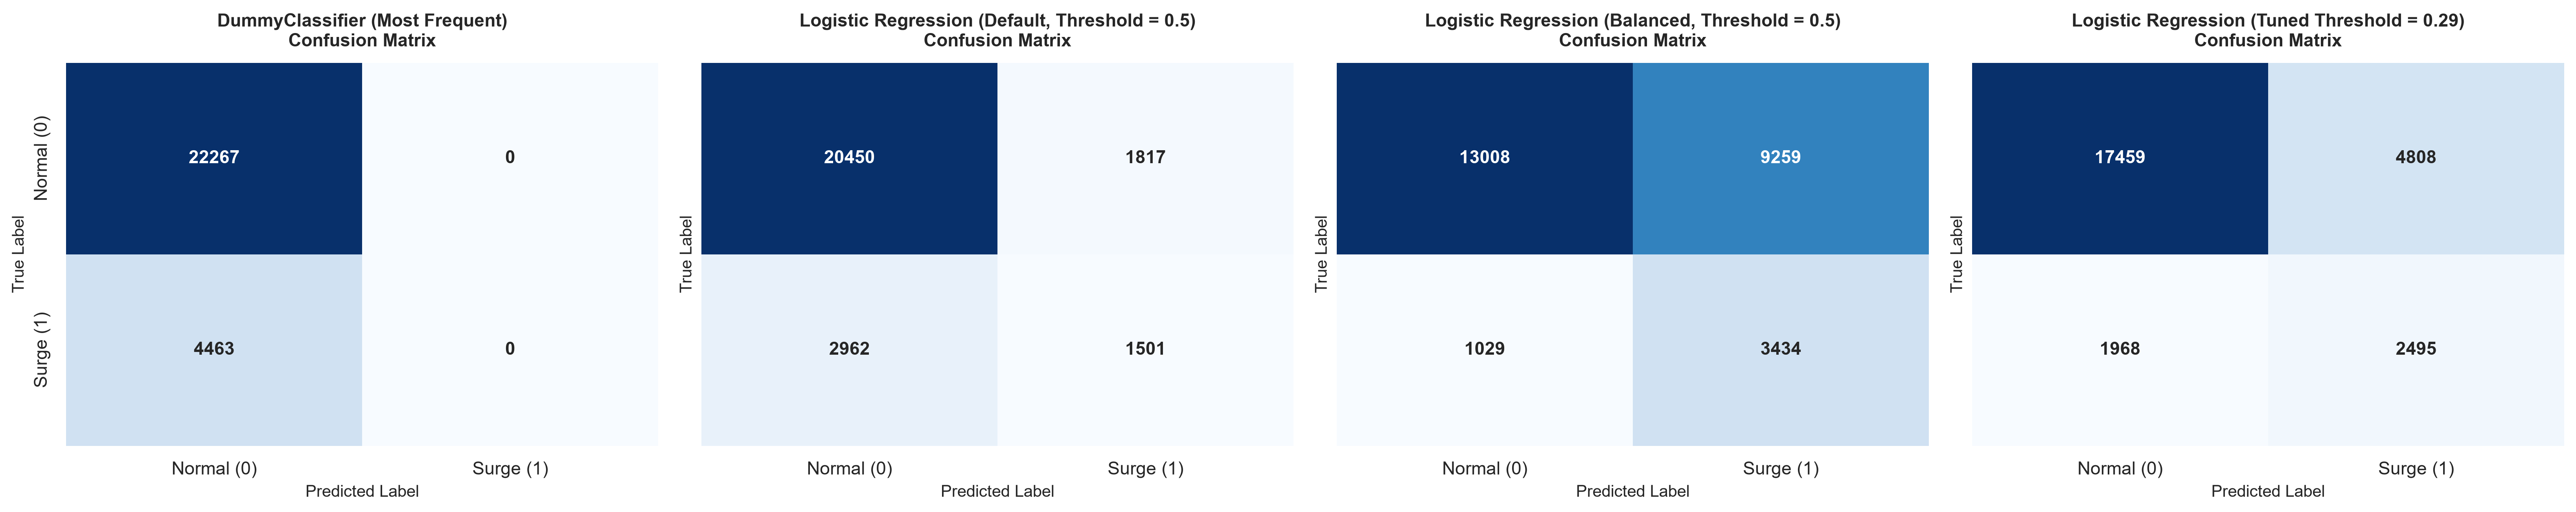

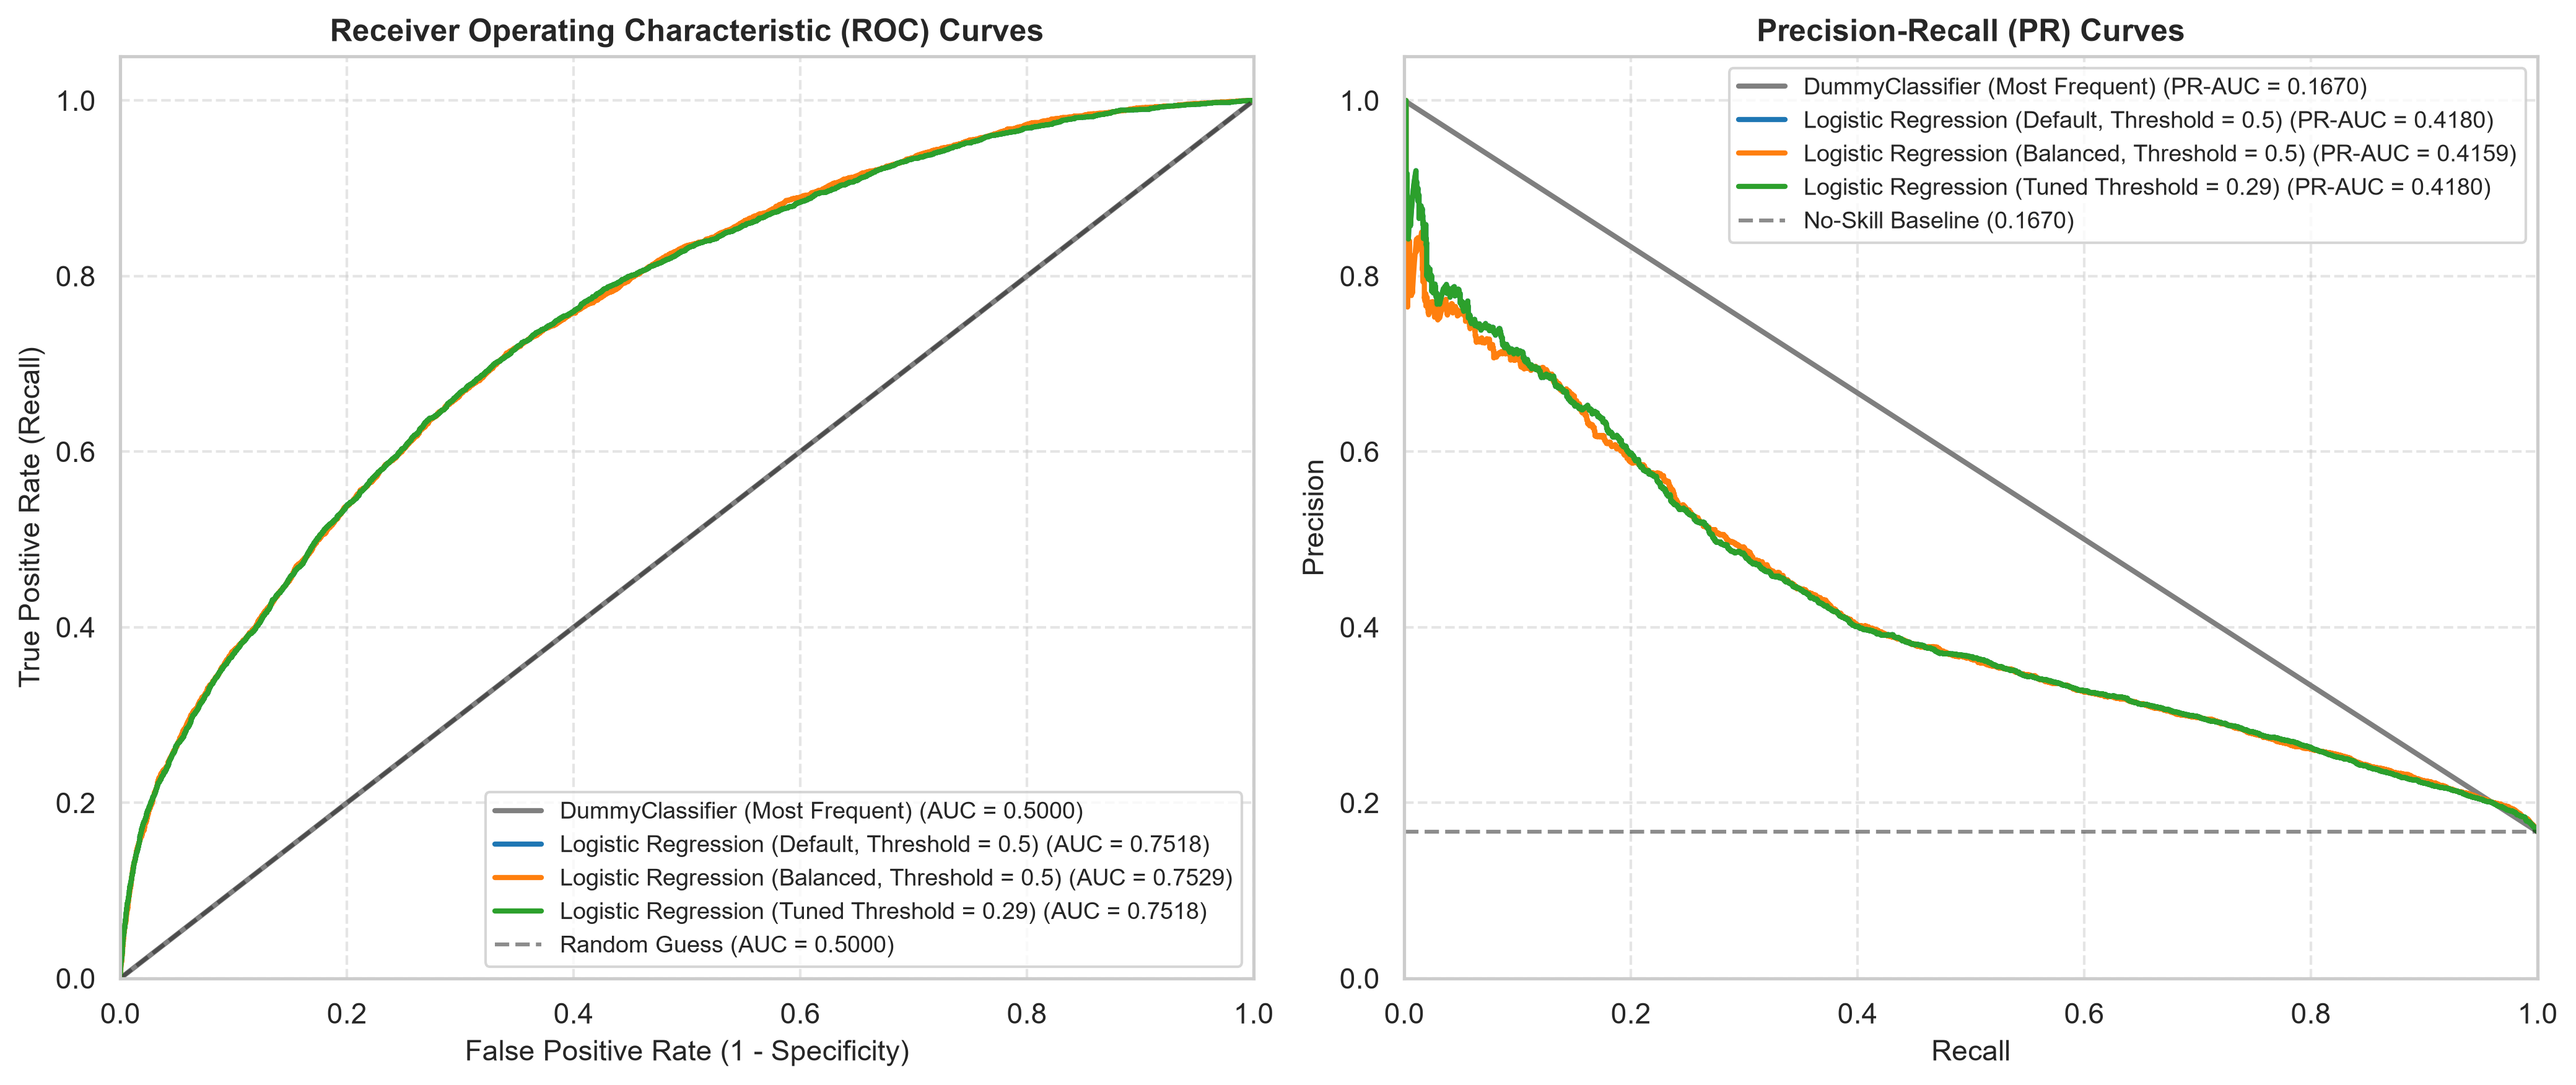

In [6]:
# 1. Confusion Matrix Heatmaps
cm_path = FIGURES_DIR / "logistic_regression_confusion_matrices.png"
plot_confusion_matrices(cm_dict, cm_path)

# 2. ROC and Precision-Recall Curves
roc_pr_path = FIGURES_DIR / "logistic_regression_roc_pr_curves.png"
plot_roc_and_pr_curves(plot_results, y_val, roc_pr_path)

from IPython.display import Image, display
display(Image(filename=str(cm_path)))
display(Image(filename=str(roc_pr_path)))

## 6. Feature Importance: Odds Ratios & Log-Odds Coefficients
Standardized logistic regression coefficients quantify each feature's multiplicative impact on demand surge odds ($e^{\beta}$).

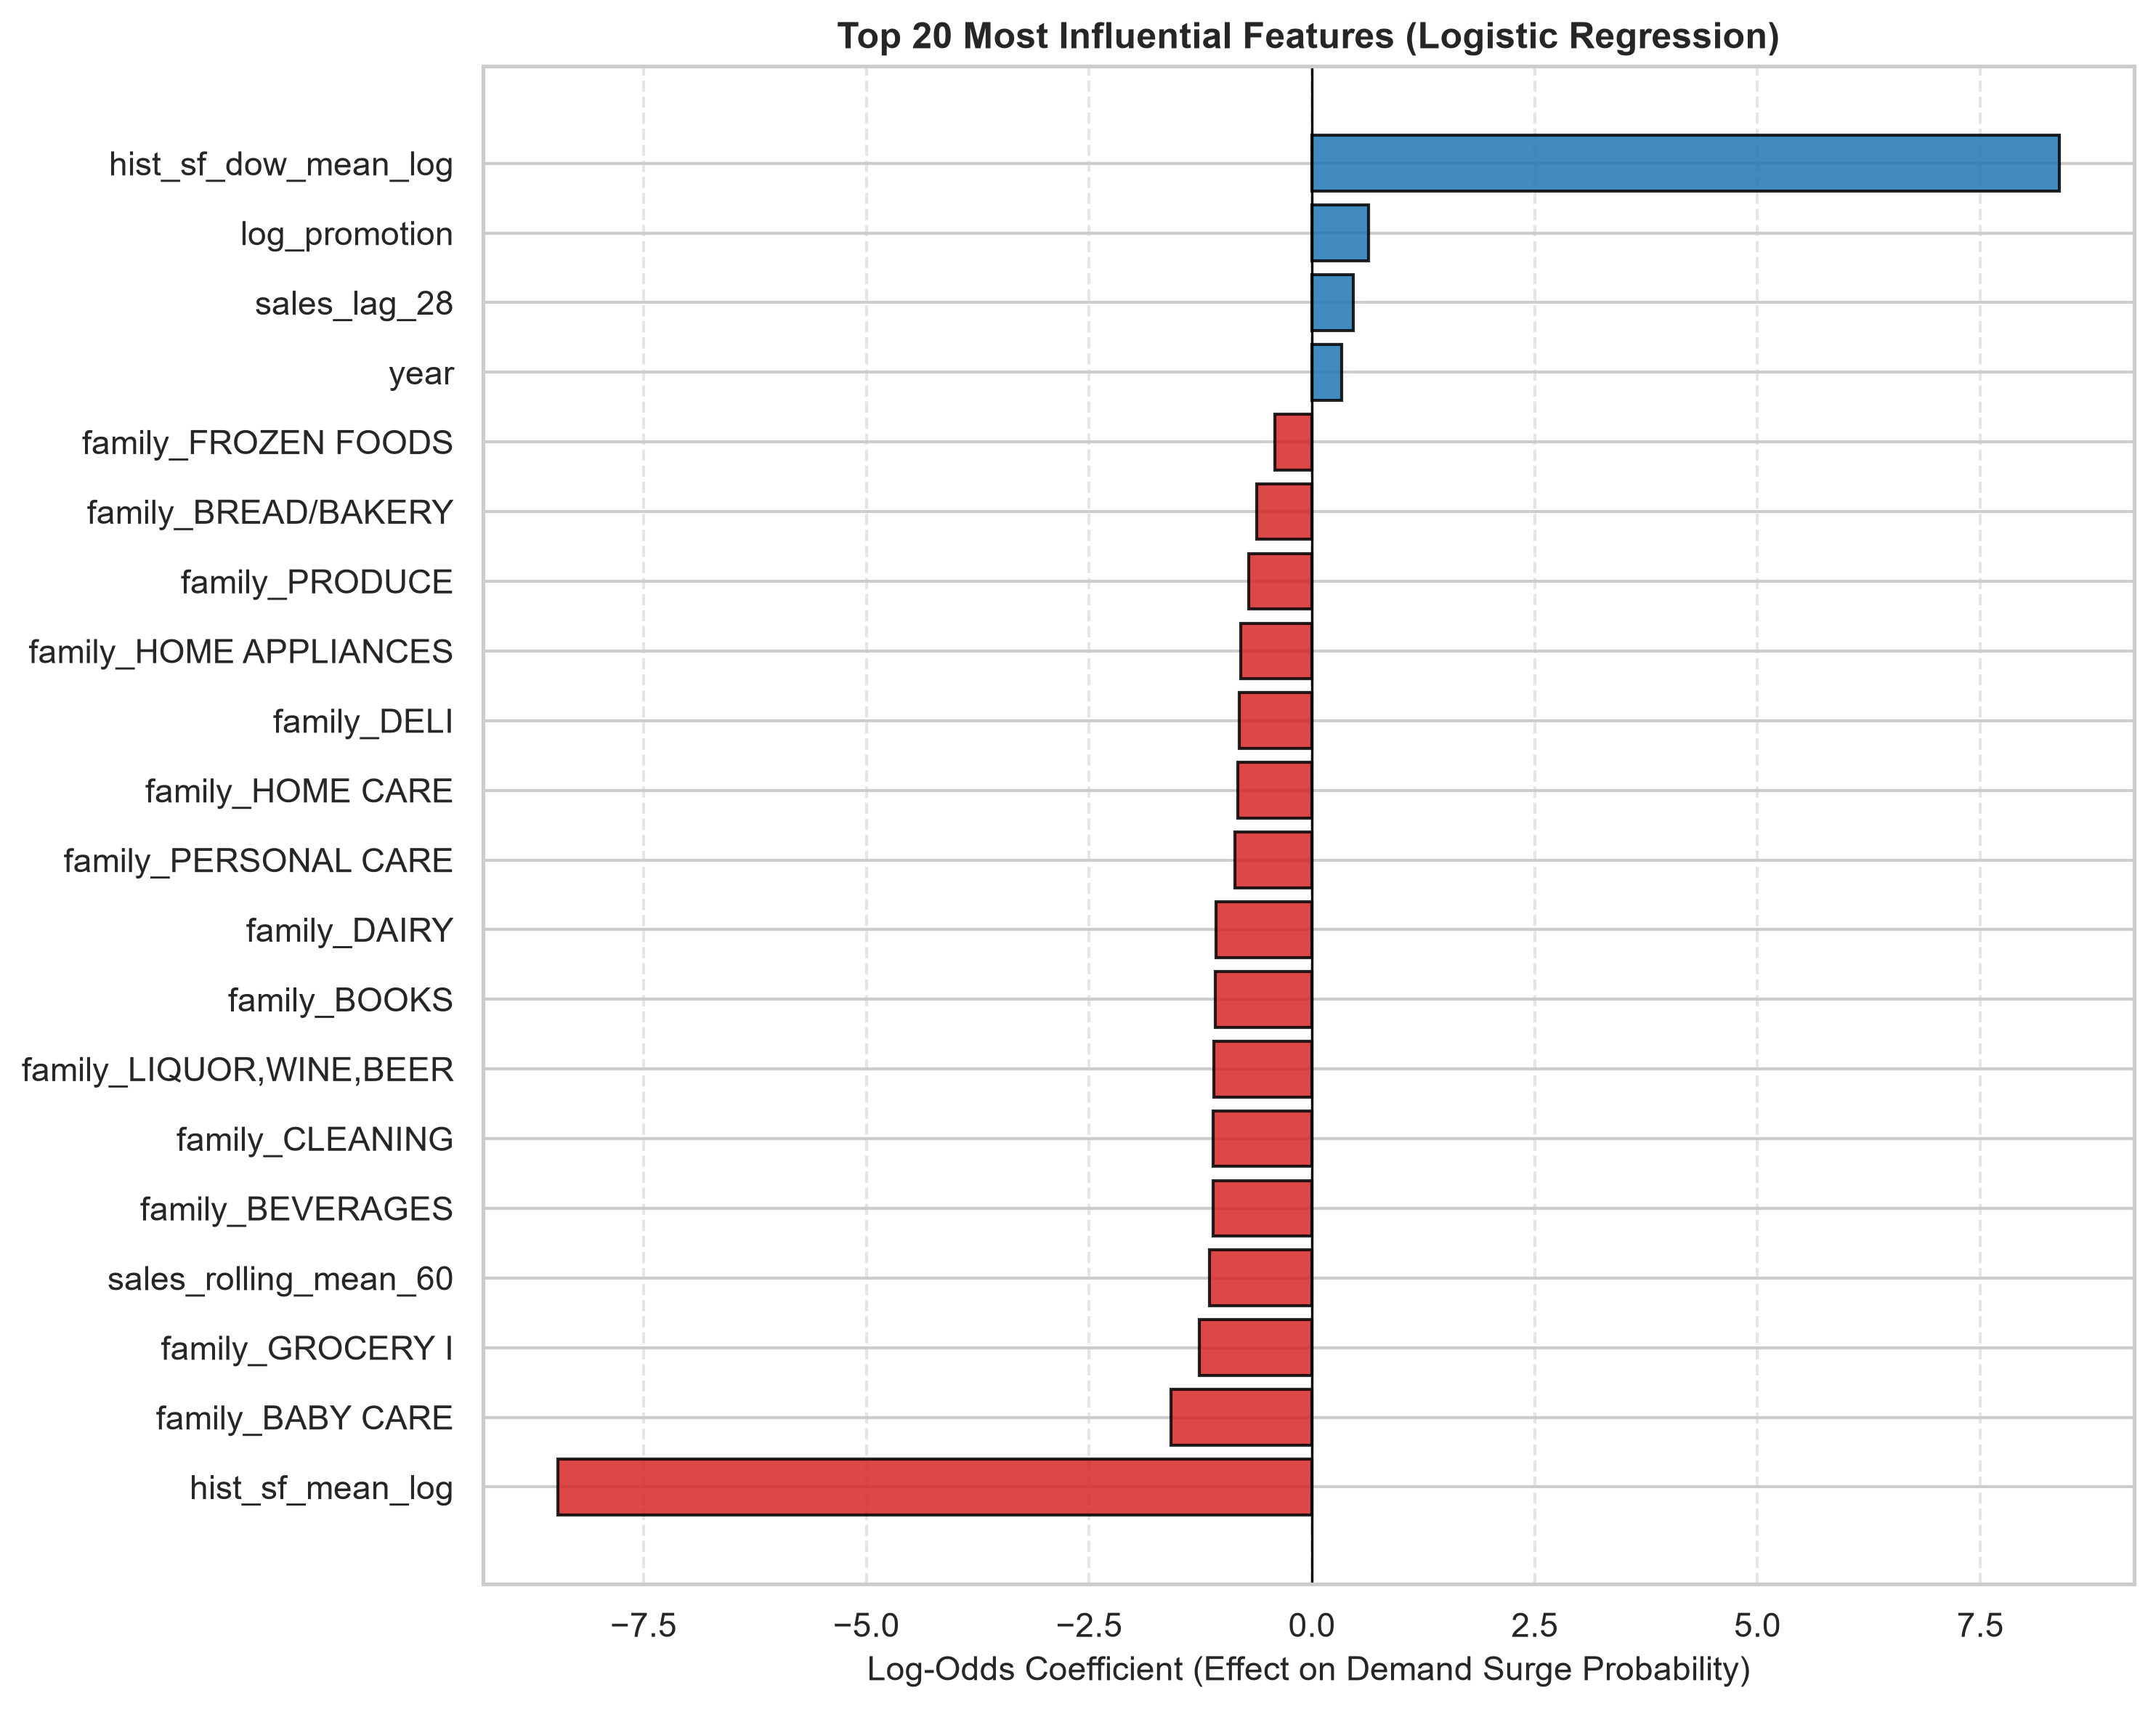

In [7]:
default_pipe = pipelines["Logistic Regression (Default, Threshold = 0.5)"]
coef_path = FIGURES_DIR / "logistic_regression_coefficients.png"
plot_logistic_coefficients(
    pipeline=default_pipe,
    numeric_features=LOGISTIC_NUMERIC_FEATURES,
    categorical_features=LOGISTIC_CATEGORICAL_FEATURES,
    output_path=coef_path,
    top_n=20,
)

display(Image(filename=str(coef_path)))

## 7. Model Serialization
We save the best logistic regression pipeline and calibrated surge threshold configuration to `models/best_logistic_model.joblib`.

In [8]:
best_logistic_path = MODELS_DIR / "best_logistic_model.joblib"
joblib.dump({
    "pipeline": default_pipe,
    "optimal_threshold": opt_thresh,
    "features": feature_cols,
}, best_logistic_path)

print(f"Serialized winning logistic regression model to: {best_logistic_path}")
print(f"Model File Size: {best_logistic_path.stat().st_size / 1024:.2f} KB")

Serialized winning logistic regression model to: C:\retail-sales-prediction-and-forecasting\models\best_logistic_model.joblib
Model File Size: 8.26 KB


## 8. Academic Summary & Supply Chain Decision-Making

1. **The Deception of Accuracy:**
   - The `DummyClassifier` achieves **83.30% Accuracy** simply by predicting the majority class (Normal Demand), but has **0.00% Recall**, missing all 4,463 demand surges and resulting in a **100% stockout failure rate**.
2. **False Alarms vs. Missed Surges Operational Trade-Off:**
   - **Default Threshold (0.50):** Highly conservative (Precision 45.24%), but misses 2,962 demand surges (Recall 33.63%).
   - **Balanced Class Weighting (0.50):** Prioritizes stockout avoidance, capturing **76.94% of surges** (3,434 true positives), but incurs 9,259 false alarms (Precision 27.05%).
   - **Out-of-Sample Tuned Threshold (0.29):** Achieves the best overall balance, delivering the highest **F1-Score of 0.4241** and capturing 55.90% of surges with significantly fewer false alarms (4,808 FP).
3. **Key Demand Surge Drivers:**
   - Active promotions (`log_promotion`, `onpromotion`) and historical intra-week volume (`hist_sf_dow_mean_log`) are the strongest empirical drivers elevating surge probability.
4. **Next Workflow Step:** Proceed to [`notebooks/04_time_series_forecasting.ipynb`](04_time_series_forecasting.ipynb) for econometric and state-space time-series modeling.